In [6]:
import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt

from pathlib import Path

In [7]:
import sys

print("Python:", sys.executable)
print("Torch:", torch.__version__)
print("HIP:", torch.version.hip)

print(
    "GPU available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Python: c:\Users\Mahed\.conda\envs\levjepa\python.exe
Torch: 2.13.0+rocm10.0.0
HIP: 7.15.26333
GPU available: True
GPU: AMD Radeon(TM) 8060S Graphics


In [8]:
Root = Path.cwd()

Data_Dir = Root / "data"

Echonet_dir = Data_Dir / "Echonet"

Videos_Dir = Echonet_dir / "videos"

Output_Dir = Root / "output"

Samples_Dir = Output_Dir / "samples"

for p in [
    Data_Dir,
    Echonet_dir,
    Videos_Dir,
    Output_Dir,
    Samples_Dir
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )


print("Project Root:", Root)
print("Videos:", Videos_Dir)
print("Output:", Output_Dir)

Project Root: d:\project\Personal\Hadi\EchoJEPA
Videos: d:\project\Personal\Hadi\EchoJEPA\data\Echonet\videos
Output: d:\project\Personal\Hadi\EchoJEPA\output


In [9]:
FileList_Path = Data_Dir / "Echonet/FileList.csv"

VolumeTracings_Path = Data_Dir / "Echonet/VolumeTracings.csv"


FileList = pd.read_csv(FileList_Path)

VolumeTracings = pd.read_csv(
    VolumeTracings_Path
)


print(
    "FileList:",
    FileList.shape
)

print(
    "VolumeTracings:",
    VolumeTracings.shape
)

FileList: (10030, 9)
VolumeTracings: (425010, 6)


In [12]:
First_Row = FileList.iloc[0]

Video_Name = First_Row["FileName"]

Video_Path = Videos_Dir / f"{Video_Name}.avi"


print(Video_Path)
print(
    "Exists:",
    Video_Path.exists()
)

d:\project\Personal\Hadi\EchoJEPA\data\Echonet\videos\0X100009310A3BD7FC.avi
Exists: True


In [14]:
import cv2

Video_Capture = cv2.VideoCapture(str(Video_Path)
)


if not Video_Capture.isOpened():
    raise Exception(
        "Cannot open video"
    )


Frame_Count = int(
    Video_Capture.get(
        cv2.CAP_PROP_FRAME_COUNT
    )
)

FPS = Video_Capture.get(
    cv2.CAP_PROP_FPS
)


Width = int(
    Video_Capture.get(
        cv2.CAP_PROP_FRAME_WIDTH
    )
)

Height = int(
    Video_Capture.get(
        cv2.CAP_PROP_FRAME_HEIGHT
    )
)


print("Frames:", Frame_Count)
print("FPS:", FPS)
print("Resolution:", Width, Height)

Frames: 174
FPS: 50.0
Resolution: 112 112


In [15]:
Number_Of_Frames = 16


Frame_Indices = np.linspace(
    0,
    Frame_Count - 1,
    Number_Of_Frames,
    dtype=int
)


Sample_Frames = []


for Frame_Index in Frame_Indices:

    Video_Capture.set(
        cv2.CAP_PROP_POS_FRAMES,
        Frame_Index
    )


    Success, Frame = Video_Capture.read()


    if not Success:
        raise Exception(
            f"Cannot read frame {Frame_Index}"
        )


    Frame_RGB = cv2.cvtColor(
        Frame,
        cv2.COLOR_BGR2RGB
    )


    Sample_Frames.append(
        (
            Frame_Index,
            Frame_RGB
        )
    )


Video_Capture.release()


print(
    "Sampled frames:",
    len(Sample_Frames)
)

Sampled frames: 16


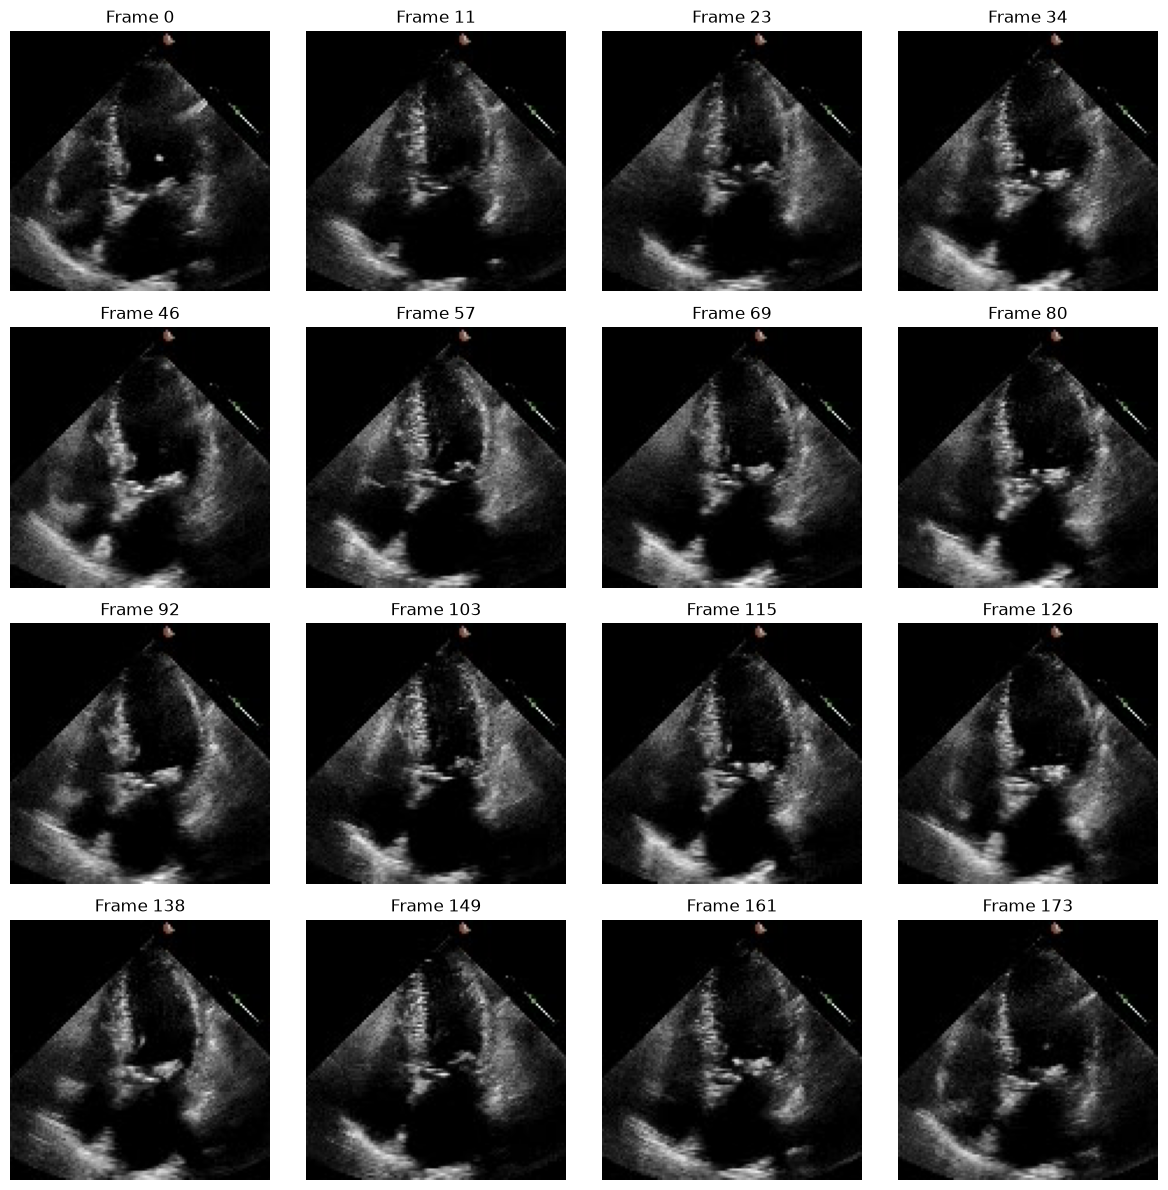

In [16]:
plt.figure(
    figsize=(12,12)
)


for i, (Frame_Index, Frame) in enumerate(Sample_Frames):

    plt.subplot(
        4,
        4,
        i+1
    )


    plt.imshow(
        Frame
    )


    plt.title(
        f"Frame {Frame_Index}"
    )


    plt.axis("off")


plt.tight_layout()
plt.show()

In [17]:
Processed_Frames = []


for Frame_Index, Frame_RGB in Sample_Frames:


    Gray_Frame = cv2.cvtColor(
        Frame_RGB,
        cv2.COLOR_RGB2GRAY
    )


    Resized_Gray_Frame = cv2.resize(
        Gray_Frame,
        (224,224),
        interpolation=cv2.INTER_LINEAR
    )


    Frame_3Channel = np.repeat(
        Resized_Gray_Frame[:, :, np.newaxis],
        3,
        axis=2
    )


    Processed_Frames.append(
        Frame_3Channel
    )



Processed_Frames = np.stack(
    Processed_Frames,
    axis=0
)


print(
    Processed_Frames.shape
)

(16, 224, 224, 3)


In [18]:
print(
    np.abs(
        Processed_Frames[:,:,:,0]
        -
        Processed_Frames[:,:,:,1]
    ).max()
)


print(
    np.abs(
        Processed_Frames[:,:,:,1]
        -
        Processed_Frames[:,:,:,2]
    ).max()
)

0
0


In [19]:
Normalized_Frames = (
    Processed_Frames.astype(np.float32)
    /
    255.0
)


print(
    Normalized_Frames.dtype
)


print(
    Normalized_Frames.min(),
    Normalized_Frames.max()
)

float32
0.0 0.99607843


In [20]:
ImageNet_Mean = np.array(
    [0.485,0.456,0.406],
    dtype=np.float32
)


ImageNet_Std = np.array(
    [0.229,0.224,0.225],
    dtype=np.float32
)


Normalized_Frames = (
    Normalized_Frames
    -
    ImageNet_Mean
) / ImageNet_Std


print(
    Normalized_Frames.shape
)

(16, 224, 224, 3)


In [21]:
Video_Tensor = torch.from_numpy(
    Normalized_Frames
)


print(
    Video_Tensor.shape
)

torch.Size([16, 224, 224, 3])


In [22]:
Video_Tensor = Video_Tensor.permute(
    3,
    0,
    1,
    2
).contiguous()


print(
    Video_Tensor.shape
)

torch.Size([3, 16, 224, 224])


In [23]:
Video_Tensor = Video_Tensor.unsqueeze(0)


print(
    Video_Tensor.shape
)

torch.Size([1, 3, 16, 224, 224])


In [24]:
assert Video_Tensor.shape == (
    1,
    3,
    16,
    224,
    224
)


assert Video_Tensor.dtype == torch.float32


assert torch.isfinite(
    Video_Tensor
).all()


print(
    "Preprocessing validation passed."
)

Preprocessing validation passed.


In [25]:
Sample_Path = (
    Samples_Dir
    /
    "sample_video_tensor.pt"
)


torch.save(
    Video_Tensor.cpu(),
    Sample_Path
)


print(
    "Saved:",
    Sample_Path
)

Saved: d:\project\Personal\Hadi\EchoJEPA\output\samples\sample_video_tensor.pt
